# hw4 research notebook - dev rao

this notebook just reads what the scripts saved (it doesn't refit anything), so run the scripts first:

```
uv run python build_data.py --db top2000
uv run python run_validation.py --db top2000
uv run python run_strategy_dev.py --db top2000
uv run python freeze_config.py ...        # see README for the exact args
uv run python run_final_test.py           # ran exactly once
uv run python run_posthoc.py
```

sections: data checks, timing evidence, features, validation, strategy choice, frozen config, final test, one lot traced by hand, reconciliation, post-hoc diagnostics.

In [1]:
import json, sys
from pathlib import Path
import duckdb, numpy as np, pandas as pd
from IPython.display import Image, display

HW = Path.cwd()
sys.path.insert(0, str(HW))
from hw4 import config, analytics as A
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)
R, O = config.RESULTS_DIR, config.OUTPUT_DIR
db = duckdb.connect(str(config.DATABASES["top2000"]), read_only=True)
cache = duckdb.connect(str(O / "cache_top2000.duckdb"), read_only=True)

## 1. data checks

table sizes match the manifest. the important thing i found: `close`, `volume` and `shares_outstanding` are split-adjusted to today's basis. so close*volume is real dollar volume (split factors cancel) but a "$5 raw price" filter would depend on future splits. i dropped that screen.

In [2]:
print({t: db.execute(f"select count(*) from {t}").fetchone()[0] for t in
       ["universe", "universe_membership", "prices", "fundamentals", "benchmark", "calendar"]})
db.execute("""select symbol, date, close, adj_close, volume, close*volume/1e6 as dollar_vol_m from prices
  where symbol in ('NVDA','AAPL') and date in ('2010-01-04','2026-09-30') order by 1,2""").fetchdf()

{'universe': 3849, 'universe_membership': 195970, 'prices': 15839788, 'fundamentals': 284198, 'benchmark': 6726, 'calendar': 6726}


,symbol,date,close,adj_close,volume,dollar_vol_m
0,AAPL,2010-01-04,7.64000,6.40000,493729600,3772.094144
1,AAPL,2026-09-30,333.02000,333.02000,49988600,16647.203572
2,NVDA,2010-01-04,0.46225,0.42108,800352640,369.963008
3,NVDA,2026-09-30,228.38000,228.38000,121732200,27801.199836


universe_rank is not reliable at the top (bad share/price units), so for the 'liquid' universe option i ranked by dollar volume instead:

In [3]:
db.execute("""select quarter_start, symbol, universe_rank, selection_close, selection_shares, market_cap_proxy/1e12 as cap_trillion
  from universe_membership where quarter_start='2016-04-01' order by universe_rank limit 4""").fetchdf()

,quarter_start,symbol,universe_rank,selection_close,selection_shares,cap_trillion
0,2016-04-01,TMBR,1,1362.50,2.103700e+10,28.662913
1,2016-04-01,IVR,2,121.80,1.228438e+11,14.962379
2,2016-04-01,KDNY,3,64.05,7.172612e+10,4.594058
3,2016-04-01,BKNG,4,1288.96,1.260075e+09,1.624186


In [4]:
print("implausible cap inputs (close > $100k or cap proxy > $5T), audit only:")
pd.read_csv(O / "audit_implausible_caps_top2000.csv").head(12)

implausible cap inputs (close > $100k or cap proxy > $5T), audit only:


,symbol,first_date,last_date,n_rows,max_close,max_cap_bn,ever_eligible
0,BRK-A,2010-01-08,2026-09-25,873,8.093500e+05,1.418887e+06,True
1,TMBR,2015-09-18,2018-06-08,79,2.225000e+03,4.680730e+04,False
2,IVR,2016-02-26,2016-05-06,12,1.299000e+02,1.595740e+04,True
3,RCA,2014-08-15,2014-11-07,13,1.490000e+00,1.590926e+04,False
4,KDNY,2015-08-14,2016-09-23,38,1.558500e+02,1.117852e+04,False
5,AVGOP,2020-08-28,2022-09-23,92,2.075390e+03,8.946545e+03,True
6,NFLX,2025-05-02,2025-09-26,21,1.323120e+03,5.781537e+03,True
7,NVDA,2026-04-24,2026-09-25,18,2.303600e+02,5.594292e+03,True
8,AAPL,2026-09-25,2026-09-25,1,3.410700e+02,5.018739e+03,True
9,INPX,2014-07-03,2019-05-24,255,7.011372e+09,3.764243e+03,False


## 2. timing evidence

the asserts live in the code (labels.py, features.py, model.py, backtester.py). here i re-check them on the whole saved panel and trace one label by hand.

In [5]:
p = cache.execute("""select date, symbol, entry_date, label_end, target, available_date, fiscal_date,
   selection_date, membership_quarter from panel""").fetchdf()
has = p.target.notna()
checks = {
  "entry strictly after signal": (p.entry_date[has] > p.date[has]).all(),
  "exit >= entry + 90 calendar days": (p.label_end[has] >= p.entry_date[has] + pd.Timedelta(days=90)).all(),
  "financials available (filing+1d) <= signal": (p.available_date.isna() | (p.available_date <= p.date)).all(),
  "membership list known at signal": (p.selection_date <= p.date).all(),
  "membership quarter = quarter of next-session entry": (p.membership_quarter[has] == p.entry_date[has].dt.to_period("Q").dt.start_time).all(),
  "no label ends after 2026-09-30": (p.label_end[has] <= pd.Timestamp("2026-09-30")).all(),
}
print(pd.Series(checks))
assert all(checks.values())

entry strictly after signal                           True
exit >= entry + 90 calendar days                      True
financials available (filing+1d) <= signal            True
membership list known at signal                       True
membership quarter = quarter of next-session entry    True
no label ends after 2026-09-30                        True
dtype: bool


In [6]:
# one label by hand: AAPL signal Thu 2013-03-28. Fri 03-29 was Good Friday, so entry is Mon 04-01.
# due = 04-01 + 90 days = Sun 06-30 -> first quote on/after is Mon 07-01.
row = cache.execute("select date, entry_date, label_end, entry_price, exit_price, target from panel where symbol='AAPL' and date='2013-03-28'").fetchdf()
px = cache.execute("select date, adj_close from px_daily where symbol='AAPL' and date between '2013-03-27' and '2013-07-02'").fetchdf().set_index('date').adj_close
print(row.T)
print("by hand:", px.loc['2013-07-01'] / px.loc['2013-04-01'] - 1)

                               0
date         2013-03-28 00:00:00
entry_date   2013-04-01 00:00:00
label_end    2013-07-01 00:00:00
entry_price                13.03
exit_price                 12.51
target                 -0.039908
by hand: -0.03990790483499618


## 3. features

35 raw features (price/technical, liquidity/size, fundamentals) + 6 sector-relative, all turned into same-date percentile ranks among eligible stocks. definitions are in the README. coverage by year (eligible rows):

In [7]:
cov = pd.read_csv(O / "audit_feature_coverage_top2000.csv", index_col=0)
cov.T.iloc[:, ::3].round(2)

year,2010,2013,2016,2019,2022,2025
rows,47053.00,56399.00,72647.00,83367.00,90718.00,95449.00
symbols,1027.00,1242.00,1550.00,1768.00,2046.00,2033.00
label_cov,1.00,1.00,1.00,1.00,0.99,0.99
mom_21,1.00,1.00,1.00,1.00,1.00,1.00
mom_63,1.00,1.00,1.00,1.00,1.00,1.00
mom_126,1.00,1.00,1.00,1.00,1.00,1.00
mom_12_1,1.00,1.00,1.00,1.00,1.00,1.00
rev_5,1.00,1.00,1.00,1.00,1.00,1.00
vol_21,1.00,1.00,1.00,1.00,1.00,1.00
vol_63,1.00,1.00,1.00,1.00,1.00,1.00


In [8]:
pd.read_csv(O / 'audit_eligibility_top2000.csv')

,y,members,eligible,dates
0,2010,99568,47053.0,52
1,2011,103113,50764.0,52
2,2012,103869,51058.0,52
3,2013,103952,56399.0,52
4,2014,103950,64632.0,52
5,2015,105971,70937.0,53
6,2016,105879,72647.0,53
7,2017,103870,76174.0,52
8,2018,103902,82453.0,52
9,2019,103895,83367.0,52


## 4. validation (2013, 2014, 2015 walk-forward, purged)

each fold fits on weekly signals from 2010 with label_end < the first signal of the validation year. first round was ridge + HGB on two targets and it was bad: basically every model had negative IC in 2013. so before trusting anything i looked at single-factor ICs by year (development data only):

In [9]:
from hw4.features import RAW_FEATURES, SECTOR_REL_FEATURES
cols = RAW_FEATURES + SECTOR_REL_FEATURES
d = cache.execute(f"select date, target, {', '.join('r_'+c for c in cols)} from panel where date between '2010-01-01' and '2015-12-31' and target is not null").fetchdf()
d["tr"] = d.groupby("date").target.rank(pct=True)
fic = pd.DataFrame({y: {c: g.groupby("date")[["r_"+c, "tr"]].corr().unstack().iloc[:, 1].mean() for c in cols}
                    for y, g in d.groupby(d.date.dt.year)})
fic["mean"] = fic.mean(axis=1)
fic.round(3).sort_values("mean")

,2010,2011,2012,2013,2014,2015,mean
share_iss,0.003,-0.083,-0.029,-0.032,-0.023,-0.052,-0.036
ivol_63,0.034,-0.063,0.000,0.069,-0.090,-0.153,-0.034
sector_mom_126,-0.041,-0.104,-0.077,0.027,-0.022,0.015,-0.034
vol_21,0.052,-0.060,-0.005,0.062,-0.105,-0.142,-0.033
vol_63,0.060,-0.064,-0.008,0.081,-0.106,-0.148,-0.031
vol_252,0.062,-0.084,-0.006,0.107,-0.097,-0.160,-0.030
max_ret_21,0.037,-0.047,-0.011,0.048,-0.077,-0.113,-0.027
bm,-0.021,-0.048,0.033,-0.055,-0.019,-0.025,-0.022
turnover_63,0.034,-0.054,0.019,0.045,-0.046,-0.126,-0.021
amihud_63,0.019,-0.012,0.007,0.023,-0.085,-0.065,-0.019


what i take from this: vol/beta factors flip sign almost every year (+0.08 in 2013, -0.15 in 2015) and momentum was negative in 2010-2012 then positive. a model fitted on 2010-2012 learns those and gets burned in 2013. the fundamentals (gross profitability, roe, earnings change, fcf yield, low issuance) are more stable. so i added (a) a beta-residual training target and (b) a fixed-sign composite with signs from published papers, nothing fitted. caveat: i designed the composite after seeing this table, so its validation IC is optimistic. the test is the only clean number.

In [10]:
cv = pd.read_csv(R / "cv_summary.csv")
cv[["model", "target_variant", "mean_IC", "min_fold_IC", "IC_t_NW13", "top_decile_excess", "decile_monotonicity", "top25_excess"]].head(12).round(4)

,model,target_variant,mean_IC,min_fold_IC,IC_t_NW13,top_decile_excess,decile_monotonicity,top25_excess
0,composite,none,0.0621,0.0116,1.5815,0.0067,0.6646,0.0064
1,ens_composite_ml,composite+ridge_a1000_resid,0.0540,-0.0416,1.2150,0.0059,0.4343,0.0035
2,ridge_a1000_resid,resid,0.0255,-0.0809,0.8896,-0.0020,0.2808,-0.0018
3,ridge_a100_resid,resid,0.0243,-0.0782,0.8511,-0.0023,0.2808,-0.0018
4,ridge_a10_resid,resid,0.0242,-0.0779,0.8470,-0.0023,0.2848,-0.0020
5,ridge_a1_resid,resid,0.0242,-0.0778,0.8466,-0.0023,0.2808,-0.0019
6,ensemble,ridge_a1000_resid+hgb_it200_lf31_ms2000_demean,0.0192,-0.0545,0.8319,-0.0016,0.2606,-0.0010
7,hgb_it200_lf31_ms2000_demean,demean,0.0078,-0.0102,0.2185,-0.0061,0.0505,-0.0096
8,hgb_it200_lf15_ms500_resid,resid,0.0076,-0.0806,0.5609,-0.0017,-0.0748,0.0054
9,hgb_it200_lf15_ms2000_resid,resid,0.0026,-0.0872,0.2544,-0.0039,-0.0707,0.0019


In [11]:
folds = pd.read_csv(R / "cv_folds.csv")
folds.loc[folds.model.isin(["composite", "ridge_a1000_resid", "hgb_it200_lf31_ms2000_demean", "ensemble", "ens_composite_ml"])] \
     .pivot(index="model", columns="fold", values="mean_IC").round(4)

fold,2013,2014,2015
model,,,
composite,0.0116,0.0612,0.1136
ens_composite_ml,-0.0416,0.0730,0.1308
ensemble,-0.0545,0.0437,0.0685
hgb_it200_lf31_ms2000_demean,-0.0102,0.0152,0.0184
ridge_a1000_resid,-0.0809,0.0546,0.1029


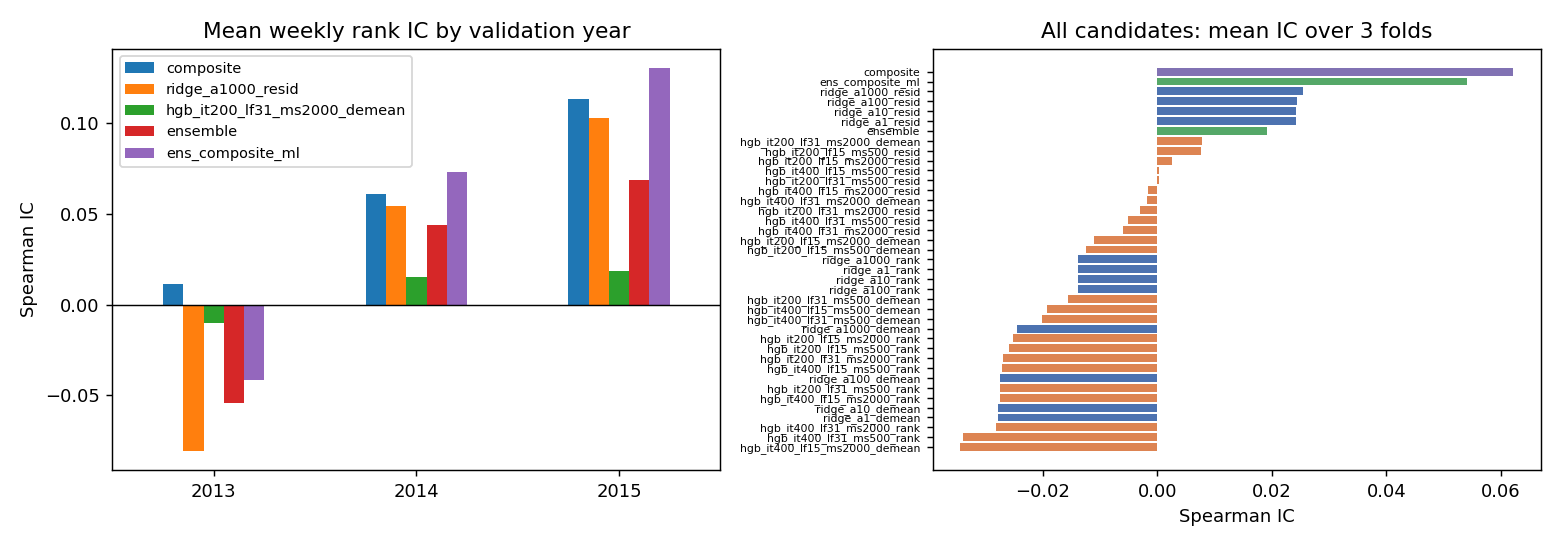

In [12]:
display(Image(R / 'cv_ic_by_fold.png'))

## 5. strategy choice (backtest 2013-2015 on the walk-forward scores)

12 configs only. picked by sharpe + excess vs benchmark, simpler wins ties. nothing beat SPX TR in development either.

In [13]:
g = pd.read_csv(R / "strategy_dev_grid_composite.csv")
g[["top_n", "cadence", "universe", "final_value", "CAGR", "sharpe", "max_drawdown", "beta", "excess_CAGR", "avg_cash_fraction"]].round(3)

,top_n,cadence,universe,final_value,CAGR,sharpe,max_drawdown,beta,excess_CAGR,avg_cash_fraction
0,10,weekly,all,1364364.782,0.110,0.758,-0.105,0.887,-0.033,0.041
1,10,weekly,liquid,1351273.959,0.106,0.732,-0.114,0.888,-0.036,0.043
2,10,monthly,all,1406252.953,0.121,0.884,-0.117,0.830,-0.022,0.111
3,10,monthly,liquid,1389212.912,0.116,0.854,-0.117,0.827,-0.026,0.110
4,25,weekly,all,1400153.142,0.119,0.830,-0.111,0.896,-0.023,0.041
5,25,weekly,liquid,1379786.369,0.114,0.790,-0.113,0.897,-0.029,0.041
6,25,monthly,all,1428225.005,0.127,0.933,-0.108,0.838,-0.016,0.109
7,25,monthly,liquid,1421080.756,0.125,0.920,-0.110,0.838,-0.018,0.110
8,50,weekly,all,1382561.612,0.114,0.795,-0.108,0.907,-0.028,0.040
9,50,weekly,liquid,1374225.850,0.112,0.778,-0.109,0.908,-0.030,0.040


## 6. frozen config (committed as frozen_config.json before any 2016+ outcome was used)

In [14]:
cfg = json.loads((HW / "frozen_config.json").read_text())
print(json.dumps({k: cfg[k] for k in ["frozen_at_utc", "strategy", "backtest", "eligibility"]}, indent=1))
print(json.dumps(cfg["model"]["themes"], indent=1))
print(json.loads((O / "final_test_ran.json").read_text()))

{
 "frozen_at_utc": "2026-11-13T19:44:39+00:00",
 "strategy": {
  "top_n": 25,
  "cadence": "monthly",
  "cohort_fraction": 0.3333333333333333,
  "universe": "all",
  "liquid_top": 1000,
  "name_cap": 0.05,
  "sector_cap": 0.3,
  "weighting": "equal within cohort; capped names pass budget to next rank",
  "cohort_budget": "min(cash + value of lots due next session, NAV * cohort_fraction)"
 },
 "backtest": {
  "initial_capital": 1000000.0,
  "fee_bps_per_side": 10.0,
  "fee_sensitivities_bps": [
   0,
   25
  ],
  "cash_interest": 0.0,
  "max_stale_sessions": 5,
  "missing_price_policy": "carry last close <= 5 sessions (flagged); longer gap => exit at last observed close (base) / 0% recovery (worst case)",
  "first_signal": "2016-03-31",
  "first_entry": "2016-04-01",
  "end": "2026-09-30",
  "annual_rf_for_sharpe": 0.02
 },
 "eligibility": {
  "dated_universe_member": true,
  "min_history_sessions": 252,
  "min_median_dollar_volume_63d": 5000000.0,
  "raw_price_screen": "none (close is

## 7. final test, 2016-04-01 to 2026-09-30 (ran once)

In [15]:
m = pd.read_csv(R / "final_metrics.csv")
show = ["portfolio", "final_value", "CAGR", "max_drawdown", "sharpe", "volatility", "beta", "tracking_error",
        "information_ratio", "avg_cash_fraction", "annual_turnover", "total_fees"]
m[show].round(4)

,portfolio,final_value,CAGR,max_drawdown,sharpe,volatility,beta,tracking_error,information_ratio,avg_cash_fraction,annual_turnover,total_fees
0,S&P 500 TR benchmark,4.402747e+06,0.1516,-0.3379,0.7725,0.1782,NaN,NaN,NaN,NaN,NaN,NaN
1,"strategy (10 bps, base)",2.599316e+06,0.0952,-0.3782,0.5143,0.1656,0.7960,0.0928,-0.5655,0.0733,3.8102,135354.5536
2,sensitivity: 0 bps,2.810242e+06,0.1034,-0.3774,0.5593,0.1656,0.7962,0.0928,-0.4854,0.0734,3.8136,0.0000
3,sensitivity: 25 bps,2.312191e+06,0.0831,-0.3794,0.4467,0.1656,0.7957,0.0930,-0.6847,0.0731,3.8049,316626.0491
4,sensitivity: 0% recovery on forced exits,1.603768e+06,0.0460,-0.3782,0.2343,0.1694,0.7936,0.1003,-0.9769,0.0703,3.7919,114569.2149
5,"sensitivity: cash earns 2%/yr (assumed, not T-...",2.639244e+06,0.0968,-0.3781,0.5230,0.1656,0.7960,0.0928,-0.5499,0.0734,3.8106,136612.0422


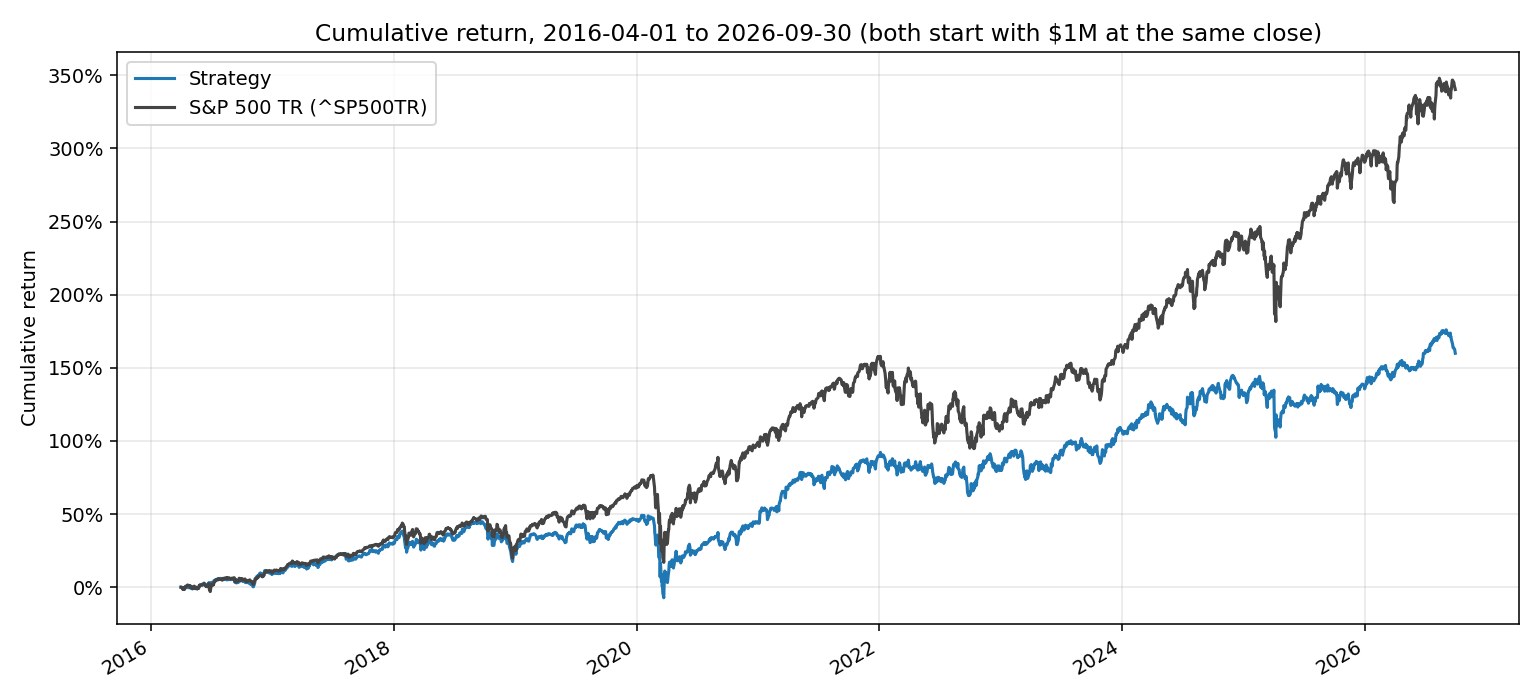

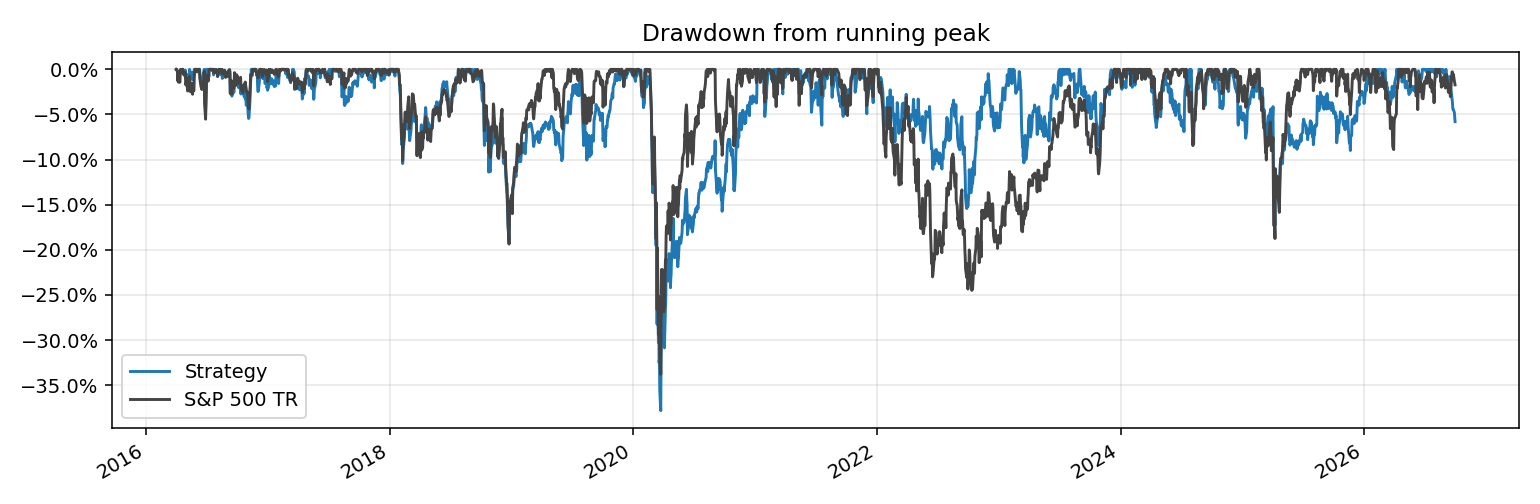

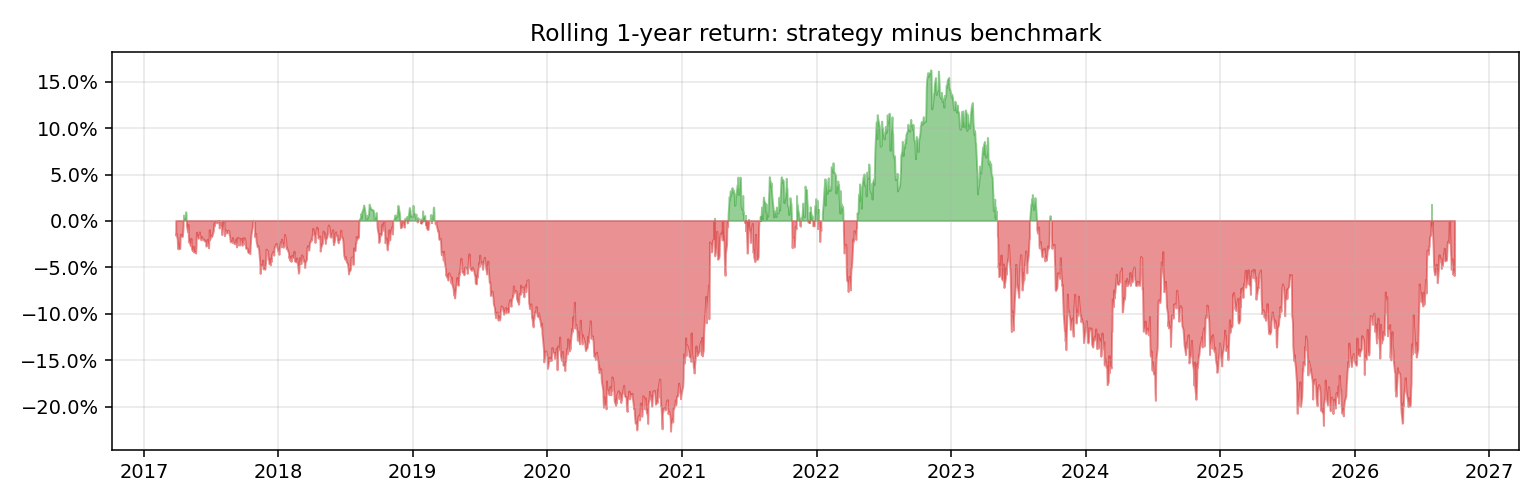

In [16]:
display(Image(R / 'cumulative_returns.png')); display(Image(R / 'drawdowns.png')); display(Image(R / 'rolling_excess.png'))

In [17]:
pd.read_csv(R / 'calendar_year_returns.csv', index_col=0).round(4)

,strategy,benchmark,excess
year,,,
2016,0.0879,0.0978,-0.0099
2017,0.1898,0.2183,-0.0285
2018,-0.0377,-0.0438,0.0061
2019,0.1722,0.3149,-0.1426
2020,-0.0096,0.1840,-0.1936
2021,0.3106,0.2871,0.0235
2022,-0.0423,-0.1811,0.1388
2023,0.1426,0.2629,-0.1202
2024,0.1183,0.2502,-0.1319


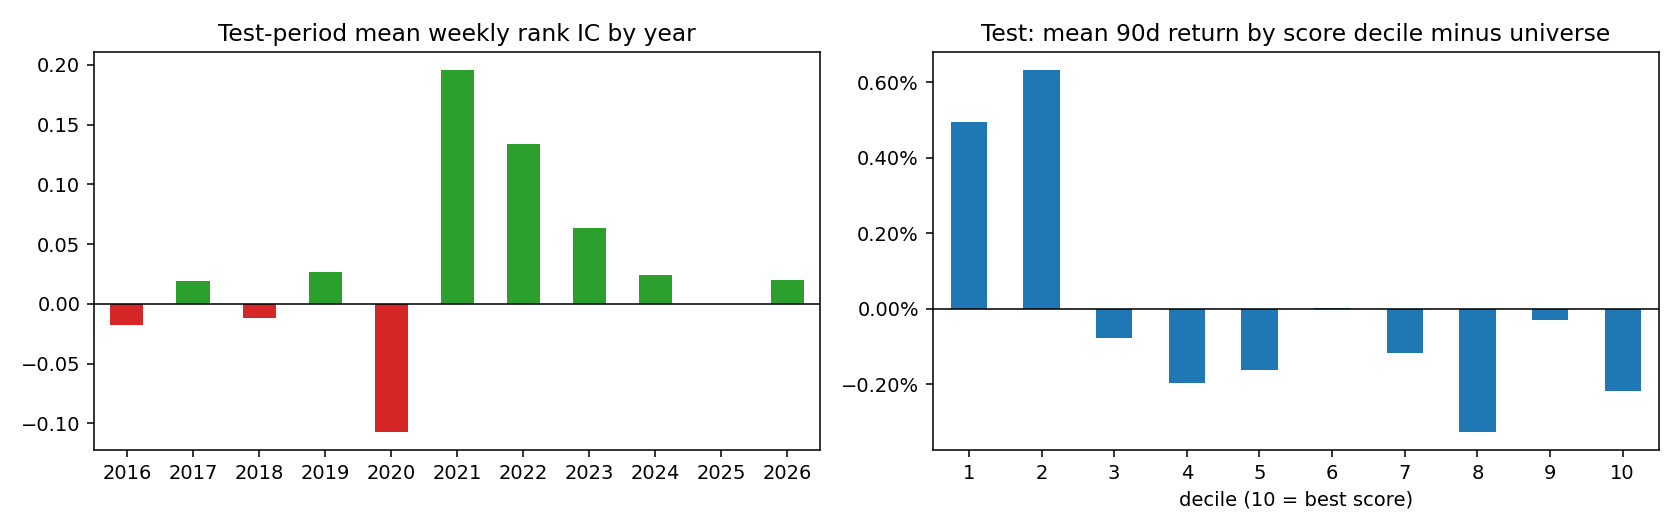

,IC,weeks
date,,
2016,-0.0175,41
2017,0.0190,52
2018,-0.0114,52
2019,0.0268,52
2020,-0.1075,53
2021,0.1955,52
2022,0.1336,52
2023,0.0634,52
2024,0.0238,52


In [18]:
display(Image(R / 'test_ic_and_deciles.png')); pd.read_csv(R / 'test_ic_by_year.csv', index_col=0).round(4)

## 8. one lot traced by hand

lot 3 of the final test: KLAC, bought from the 2016-03-31 signal. budget per name = NAV/3/25 = 1,000,000/75 = 13,333.33 (fee-inclusive), fee 10 bps.

In [19]:
lots = pd.read_csv(O / "final_lots.csv", parse_dates=["signal_date", "entry_date", "due_date", "exit_date"])
fills = pd.read_csv(O / "final_fills.csv", parse_dates=["date", "signal_date"])
lot = lots.loc[lots.lot_id == 3].iloc[0]
px = cache.execute("select date, adj_close from px_daily where symbol='KLAC' and date between '2016-03-30' and '2016-07-01'").fetchdf().set_index("date").adj_close
budget, fee = 1_000_000 / 3 / 25, 0.001
entry = px.loc["2016-04-01"]                  # next session after the signal
units = budget / (entry * (1 + fee))
buy_fee = units * entry * fee
due = pd.Timestamp("2016-04-01") + pd.Timedelta(days=90)   # 2016-06-30, a Thursday
exit_px = px.loc[due]
proceeds = units * exit_px * (1 - fee)
pnl = proceeds - budget
hand = pd.Series({"signal close (not used for the fill)": px.loc["2016-03-31"], "entry price 04-01": entry, "units": units,
                  "entry fee": buy_fee, "due date": due.date(), "exit price": exit_px, "sale fee": units * exit_px * fee,
                  "proceeds": proceeds, "realized pnl": pnl})
print(hand)
print(lot[["entry_date", "due_date", "exit_date", "entry_price", "exit_price", "units", "cost", "proceeds", "realized_pnl"]])
assert np.isclose(units, lot.units) and np.isclose(pnl, lot.realized_pnl) and lot.exit_date == due

signal close (not used for the fill)           62.16
entry price 04-01                              62.36
units                                     213.598674
entry fee                                  13.320013
due date                                  2016-06-30
exit price                                      63.0
sale fee                                   13.456716
proceeds                                13443.259755
realized pnl                              109.926422
dtype: object
entry_date      2016-04-01 00:00:00
due_date        2016-06-30 00:00:00
exit_date       2016-06-30 00:00:00
entry_price                   62.36
exit_price                     63.0
units                    213.598674
cost                   13333.333333
proceeds               13443.259755
realized_pnl             109.926422
Name: 2, dtype: object


## 9. reconciliation on the full final run

In [20]:
h = pd.read_csv(O / "final_history.csv", index_col=0, parse_dates=True)
cash = 1_000_000 + fills.groupby("date").cash_change.sum().reindex(h.index, fill_value=0).cumsum()
recon = {
  "cash rebuilt from fills == ledger cash (max abs diff)": float((cash - h.cash).abs().max()),
  "NAV - 1M - (realized + unrealized) (max abs diff)": float((h.nav - 1e6 - h.realized_pnl_cum - h.unrealized_pnl).abs().max()),
  "fees in fills - fees in history": float(fills.fee.sum() - h.fees.sum()),
  "min cash": float(h.cash.min()),
  "fills on/before signal date": int((fills.date <= fills.signal_date).sum()),
  "maturity lots held < 90 days": int(((lots.exit_date - lots.entry_date).dt.days < 90)[lots.exit_reason == "maturity"].sum()),
  "first row is initial capital": bool(h.nav.iloc[0] == 1e6 and h.open_lots.iloc[0] == 0),
}
print(pd.Series(recon))
print(pd.read_csv(O / "final_diagnostics.csv").event.value_counts())

cash rebuilt from fills == ledger cash (max abs diff)     0.0
NAV - 1M - (realized + unrealized) (max abs diff)         0.0
fees in fills - fees in history                          -0.0
min cash                                                  0.0
fills on/before signal date                                 0
maturity lots held < 90 days                                0
first row is initial capital                             True
dtype: object
event
forced_exit          38
reduced_to_cash      23
rejected_no_quote     1
Name: count, dtype: int64


## 10. post-hoc diagnostics (after the one test, don't change the headline)

why did we lose? first: same rules/costs/caps but random picks from the same eligible universe (20 seeds).

In [21]:
pd.read_csv(R / 'posthoc_random_pick_null.csv', index_col=0).round(4)

,strategy,random_25_mean,random_25_min,random_25_max,benchmark
final_value,2.599316e+06,2.669160e+06,2.065102e+06,3.526816e+06,4.402747e+06
CAGR,9.520000e-02,9.710000e-02,7.150000e-02,1.275000e-01,1.516000e-01
sharpe,5.143000e-01,4.604000e-01,3.448000e-01,5.868000e-01,7.725000e-01
max_drawdown,-3.782000e-01,-4.284000e-01,-4.587000e-01,-3.800000e-01,-3.379000e-01
strategy_CAGR_percentile_vs_random,4.500000e-01,NaN,NaN,NaN,NaN


so random 25-name portfolios also lag SPX by about the same amount. the gap is mostly universe/weighting (equal-weight mid/large caps vs a cap-weighted index full of mega-cap tech), not the ranking. our picks were around the median random portfolio, with a smaller drawdown.

In [22]:
pd.read_csv(R / 'posthoc_decile_table.csv', index_col=0).round(4)

,mean_excess,median_excess,mean_ret,hit_rate
decile,,,,
1,0.0051,-0.0328,0.0384,0.4479
2,0.0065,-0.0135,0.0398,0.4710
3,-0.0008,-0.0119,0.0325,0.4698
4,-0.0021,-0.0105,0.0312,0.4710
5,-0.0018,-0.0085,0.0315,0.4746
6,-0.0001,-0.0060,0.0333,0.4807
7,-0.0012,-0.0063,0.0321,0.4792
8,-0.0033,-0.0074,0.0301,0.4748
9,-0.0003,-0.0041,0.0330,0.4863


median excess and hit rate go up with the score (so the IC is real), but the *mean* return of the worst decile is the highest because junk stocks have fat right tails. a long-only top-25 book earns the mean, not the median.

In [23]:
pd.read_csv(R / 'posthoc_top25_vs_universe_by_year.csv', index_col=0).round(4)

,rest_of_universe,top25_picks,picks_minus_rest
date,,,
2016,0.0574,0.0547,-0.0026
2017,0.0408,0.0376,-0.0032
2018,0.0070,0.0176,0.0106
2019,0.0054,-0.0042,-0.0096
2020,0.1211,0.0623,-0.0588
2021,0.0095,0.0427,0.0332
2022,-0.0132,0.0019,0.0151
2023,0.0364,0.0461,0.0097
2024,0.0282,0.0274,-0.0008


In [24]:
print(pd.read_csv(R / 'exposures.csv', index_col=0).round(3))
pd.read_csv(R / 'sector_weights.csv', index_col=0).round(3)

                purchases_cost_weighted  eligible_universe
r_log_mcap                        0.609                0.5
r_log_dv_63                       0.584                0.5
r_beta_252                        0.341                0.5
r_vol_63                          0.235                0.5
r_mom_12_1                        0.657                0.5
r_bm                              0.509                0.5
r_ey                              0.728                0.5
r_gp_a                            0.657                0.5
r_roe                             0.724                0.5
r_asset_growth                    0.261                0.5
r_share_iss                       0.177                0.5


,strategy_purchases,eligible_universe_rows
sector,,
Basic Materials,0.076,0.050
Communication Services,0.041,0.039
Consumer Cyclical,0.132,0.124
Consumer Defensive,0.092,0.050
Energy,0.072,0.056
Financial Services,0.167,0.146
Healthcare,0.086,0.132
Industrials,0.164,0.139
Real Estate,0.021,0.077


In [25]:
pd.read_csv(R / 'forced_exits_classified.csv', index_col=0).round(0)

,lots,cost,exit_value,pnl,likely_event_not_from_db
symbol,,,,,
AEL,2,59186.0,59470.0,284.0,cash+stock acquisition by Brookfield (2024)
AHL,3,95004.0,95763.0,759.0,likely acquisition (unverified)
CERN,3,50822.0,51053.0,230.0,cash acquisition by Oracle (2022)
CHK,1,30588.0,34574.0,3986.0,merger with Southwestern -> Expand Energy (tic...
DCP,1,24077.0,24081.0,4.0,bought in by Phillips 66 (2023)
EA,2,67852.0,68945.0,1093.0,"take-private (2026, announced 2025)"
FOE,1,2343.0,2368.0,24.0,cash acquisition by Prince (2022)
HIBB,1,28669.0,28743.0,74.0,cash acquisition by JD Sports (2024)
MEG,1,14505.0,14245.0,-260.0,2017 Media General -> Nexstar; ticker later re...
